##Deliverable 1 in INF 201

#Task 1: 

Summary of temperatures this year (2025) in Ås:
Mean temperature of the year:               7.9°C 
Median temperature of the year:             8.4°C 
Lowest temperature of the year:           -15.5°C
Highest temperature of the year:           23.7°C


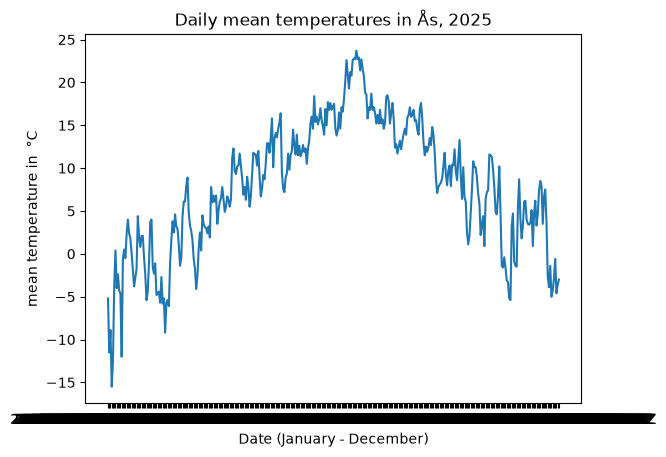

In [ ]:
""" Takes the daily mean temperature in Ås in 2025, from frost.met.no
and turns it into a graph. It also calculates mean, median, highest and lowest
temperature of 2025, and prints out the results.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests

file_path = Path.home() / 'INF201' / 'FrostID.txt'
with open(file_path, "r") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, params=parameters, auth=(client_id, ''), timeout=10)
json_data = r.json()

if r.status_code == 200:
    xtime: list[str] = []
    ytemperature: list[float]= []

    for day in json_data['data']:
        date = day['referenceTime']
        temp = day['observations'][0]['value']
    
        xtime.append(date)
        ytemperature.append(temp)

    mean_year_temp = np.mean(ytemperature)
    median_year_temp = np.median(ytemperature)
    min_year_temp = np.min(ytemperature)
    max_year_temp = np.max(ytemperature)
        
    print("Summary of temperatures this year (2025) in Ås:")
    print(f"{'Mean temperature of the year:' :<33} {mean_year_temp:>13.1f}°C ")
    print(f"{'Median temperature of the year:' :<33} {median_year_temp:>13.1f}°C ")
    print(f"{'Lowest temperature of the year:' :<33} {min_year_temp:>13.1f}°C")
    print(f"{'Highest temperature of the year:' :<33} {max_year_temp:>13.1f}°C")

    plt.plot(xtime, ytemperature)
    plt.title('Daily mean temperatures in Ås, 2025')
    plt.xlabel('Date (January - December)')
    plt.ylabel('mean temperature in  °C')
    plt.show()

else:
    print(f"Something happened! statuscode: {r.status_code}")
    print(json_data.get('error', {}).get('message'))


Refrences: 
Meteorologisk institutt (u.å) https://frost.met.no/python_example.html Python example script Hentet[15.10.2026]
From this source i used these lines in my code:  
"import requests"
"r = requests.get(endpoint, params=parameters, auth=(client_id, ''))"
"json_data = r.json()"
"if r.status_code == 200:"

And this is pasted in from the task: 
"endpoint = 'https://frost.met.no/observations/v0.jsonld'"
"parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}"


#Task 2: 

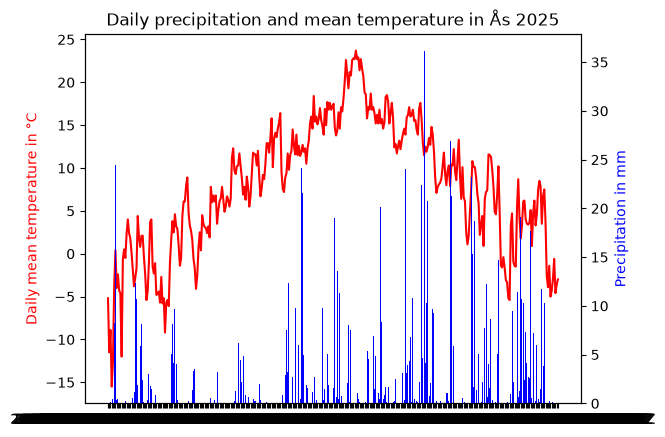

In [2]:
"""Take mean daily temperature and daily precipitation from frost.met.no
and make a graph with both variables.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import requests

file_path = Path.home() / 'INF201' / 'FrostID.txt'
with open(file_path, "r") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters_temp = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}
parameters_precip = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, params=parameters_temp, auth=(client_id, ''), timeout=10)
json_data = r.json()

r1 = requests.get(endpoint, params=parameters_precip, auth=(client_id, ''), timeout=10)
json_data1 = r1.json() 

if r.status_code == 200:
    xtime: list[str] = []
    ytemperature: list[float] = []

    for day in json_data['data']:
        date = day['referenceTime']
        temp = day['observations'][0]['value']
    
        xtime.append(date)
        ytemperature.append(temp)

else:
    print(f"Something happened! statuscode: {r.status_code}")
    print(json_data.get('error', {}).get('message'))

if r1.status_code == 200:
    all_precipitation: list[float] = []

    for precip in json_data1['data']:
        precipitation = precip['observations'][0]['value']
        all_precipitation.append(precipitation)

else:
    print(f"Something happened! statuscode: {r1.status_code}")
    print(json_data1.get('error', {}).get('message'))

fig, ax1 = plt.subplots()
ax1.plot(xtime, ytemperature, color='red', label='temperature')
ax1.set_ylabel('Daily mean temperature in °C', color='red')

ax2 = ax1.twinx()
ax2.bar(xtime, all_precipitation, color='blue', label='precipitation')
ax2.set_ylabel("Precipitation in mm", color='blue')

plt.xlabel('Date (January - December)')
plt.title("Daily precipitation and mean temperature in Ås 2025")
plt.show()



#Task 3: 

Summary of temperatures for year 1925 and 2025 in Ås:
Mean temperature for            1925:   5.3°C    2025:   7.9°C 
Median temperature for          1925:   5.3°C    2025:   8.4°C 
Lowest temperature for          1925: -20.7°C    2025: -15.5°C 
Highest temperature for         1925:  24.3°C    2025:  23.7°C 


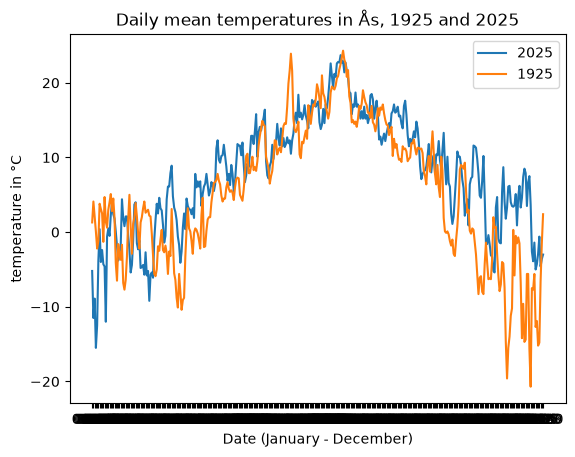

In [ ]:
"""Compare daily mean temperature in Ås in 2025 and 1925 using data from frost.met.no and 
calculate mean, median, highest and lowest temperature of both years.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import requests

file_path = Path.home() / 'INF201' / 'FrostID.txt'
with open(file_path, "r") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters_100y = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '1925-01-01/1925-12-31',
}

parameters_2025 = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r_100y = requests.get(endpoint, params=parameters_100y, auth=(client_id, ''), timeout=10)
json_data100 = r_100y.json()

r_2025 = requests.get(endpoint, params=parameters_2025, auth=(client_id, ''), timeout=10)
json_data25 = r_2025.json()

if r_100y.status_code == 200 and r_2025.status_code == 200:
    xtime100: list[str] = []
    ytemperature100: list[float] = []

    for day in json_data100['data']:
        date100 = day['referenceTime']
        temp100 = day['observations'][0]['value']
    
        xtime100.append(date100)
        ytemperature100.append(temp100)

    mean_year_temp100 = np.mean(ytemperature100)
    median_year_temp100 = np.median(ytemperature100)
    min_year_temp100 = np.min(ytemperature100)
    max_year_temp100 = np.max(ytemperature100)

    xtime: list[str] = []
    ytemperature: list[float] = []
        
    xtime_no_year: list[str] = []
    
    for day in json_data25['data']:
        full_date = day['referenceTime']
        temp = day['observations'][0]['value']
    
        date_no_year = full_date[5:10]
        
        xtime.append(full_date)
        ytemperature.append(temp)
    
        xtime_no_year.append(date_no_year)
    
    mean_year_temp = np.mean(ytemperature)
    median_year_temp = np.median(ytemperature)
    min_year_temp = np.min(ytemperature)
    max_year_temp = np.max(ytemperature)


    print("Summary of temperatures for year 1925 and 2025 in Ås:")
    print(f"{'Mean temperature for':<32}1925:  {mean_year_temp100:>4.1f}°C    2025:  {mean_year_temp:>4.1f}°C ")
    print(f"{'Median temperature for':<32}1925:  {median_year_temp100:>4.1f}°C    2025:  {median_year_temp:>4.1f}°C ")
    print(f"{'Lowest temperature for':<32}1925: {min_year_temp100:>4.1f}°C    2025: {min_year_temp:>4.1f}°C ")
    print(f"{'Highest temperature for':<32}1925:  {max_year_temp100:>4.1f}°C    2025:  {max_year_temp:>4.1f}°C ")

    plt.plot(xtime_no_year, ytemperature, xtime_no_year, ytemperature100)
    plt.legend(['2025', '1925'])
    plt.title('Daily mean temperatures in Ås, 1925 and 2025')
    plt.xlabel('Date (January - December)')
    plt.ylabel('temperature in °C')
    plt.show()

else:
    print(f"Something happened! statuscode 2025: {r_2025.status_code} statuscode 1925: {r_100y.status_code}")
    print(json_data25.get('error', {}).get('message'),)
    print(json_data100.get('error', {}).get('message'))




Task 4: 

In [2]:
from pathlib import Path

import requests
import yaml

file_path = Path.home() / 'INF201' / 'FrostID.txt'
with open(file_path, "r") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'


def heatwave_count(station_id, station_name, year):
    """Count number of heatwaves in a year with data from frost.met.no. 
    
    A heatwave is defined here as 5 or more consecutive days above 27 °C. 
    Makes a summary YAML file with the findings.
    """
    parameters = {
        'sources': station_id,
        'elements': 'max(air_temperature P1D)',
        'referencetime': f'{year}-01-01/{year}-12-31',
    }

    r = requests.get(endpoint, params=parameters, auth=(client_id, ''), timeout=10)
    json_data = r.json()

    heatwave = 0
    consecutive_days = 0
    current_heatwave_dates = []
    actual_heatwave_dates = []
    if r.status_code == 200 and 'data' in json_data: 
        for d in json_data['data']:
            temp = d['observations'][0]['value']
            date = d['referenceTime'][:10]

            if temp >= 27: 
                consecutive_days += 1
                current_heatwave_dates.append(date)

                if consecutive_days == 5: 
                    heatwave += 1
            else:
                consecutive_days = 0
                if len(current_heatwave_dates) >= 5:
                    actual_heatwave_dates.append(current_heatwave_dates)
                current_heatwave_dates = []
        
        if len(current_heatwave_dates) >= 5:
            actual_heatwave_dates.append(current_heatwave_dates)
        
        summary = {
            'dates': [f"{wave[0]} - {wave[-1]}" for wave in actual_heatwave_dates],
            'station_id': station_id,
            'station_name': station_name,
            'year': year,
        }
    
        filename = f"Heatwaves_summary_{station_id},{year}.yml"
        with open(filename, 'w') as ymlfile:
            yaml.dump(summary, ymlfile, sort_keys=False, allow_unicode=True)
        
        return heatwave
    
    else:
        print(f"something went wrong, couldn't find data for {station_id} in {year}. Status: {r.status_code} ")
        return 0

print(f"number of heatwaves:{heatwave_count('SN17850', 'Ås', 2025)}")


number of heatwaves:1


screnshot of the YAMl file: 
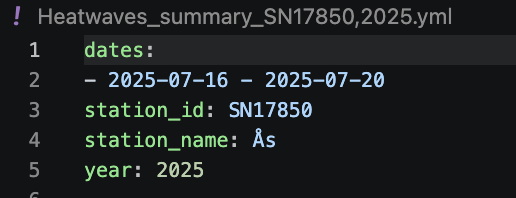